<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/02_time_series/02_forecasting_app_bike_demand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚲 Application · Forecasting bike demand: gradient boosting vs a foundation model

**Washington D.C., 2011.** Capital Bikeshare has thousands of bikes spread over hundreds of stations. Every morning,
vans move bikes from full stations to empty ones (*rebalancing*). Too few bikes at 8 a.m. near the metro and
commuters walk away; too many in the evening and returning riders can't dock. To plan the vans, the operator needs
to know **how many rentals will happen in each of the next 24 hours**.

In 2013, researchers Hadi Fanaee-T and João Gama published two years of hourly rentals with the weather, and in
2014 Kaggle launched the **Bike Sharing Demand** competition on it. It became a classic because it hides every
lesson of time-series forecasting: daily and weekly cycles, growth, weather, holidays, storms…

**Our mission:** every night at midnight, forecast the next 24 hours of rentals, for each day of December 2012.

**The plan, and why each phase matters**

| Phase | Why |
|---|---|
| 1. Load & repair the time index | models need one row per hour; missing hours tell a story |
| 2. EDA | find the cycles a model must learn |
| 3. Frame the forecast | what is known at midnight? this decides the features (and avoids leakage) |
| 4. Baselines | "same hour yesterday / last week" |
| 5. Gradient boosting with lag features (direct strategy) | the approach that wins most forecasting competitions |
| 6. Recursive strategy | the alternative, and its error accumulation |
| 7. Chronos, a zero-shot foundation model | a pretrained "GPT for time series", no training at all |
| 8. Ensemble & conclusions | combine strengths |

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "chronos-forecasting"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
import warnings
warnings.filterwarnings("ignore")

quest("Forecast bike demand", chapter="Track 2 · Time series · Forecasting (application)", xp=250)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Forecast bike demand
   Track 2 · Time series · Forecasting (application)
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load the data and repair the time index 📥

The UCI archive gives one row per hour with the date (`dteday`), the hour (`hr`), calendar flags, the weather and
the number of rentals `cnt` (= `casual` + `registered` users).

In [3]:
folder = download_and_extract("https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip",
                              "bike_sharing", marker="hour.csv")
raw = pd.read_csv(folder / "hour.csv")
raw["timestamp"] = pd.to_datetime(raw["dteday"]) + pd.to_timedelta(raw["hr"], unit="h")
raw = raw.set_index("timestamp")
print(f"{len(raw)} hourly rows from {raw.index.min()} to {raw.index.max()}")
raw[["season", "holiday", "workingday", "weathersit", "temp", "hum", "windspeed", "casual", "registered", "cnt"]].head()

17379 hourly rows from 2011-01-01 00:00:00 to 2012-12-31 23:00:00


,season,holiday,workingday,weathersit,temp,hum,windspeed,casual,registered,cnt
timestamp,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,0.24,0.81,0.0,3,13,16
2011-01-01 01:00:00,1,0,0,1,0.22,0.80,0.0,8,32,40
2011-01-01 02:00:00,1,0,0,1,0.22,0.80,0.0,5,27,32
2011-01-01 03:00:00,1,0,0,1,0.24,0.75,0.0,3,10,13
2011-01-01 04:00:00,1,0,0,1,0.24,0.75,0.0,0,1,1


Two years contain 17 544 hours, so some hours are **missing**. Which days?

In [4]:
full_index = pd.date_range(raw.index.min(), raw.index.max(), freq="h")
missing = full_index.difference(raw.index)
print(f"{len(missing)} missing hours. Days with the most missing hours:")
pd.Series(missing.date).value_counts().head(5)

165 missing hours. Days with the most missing hours:


2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
Name: count, dtype: int64

Missing data always has a story. **October 29-30, 2012** is *Hurricane Sandy*: the system was shut down.
**January 26-27, 2011** is a severe snowstorm in Washington, and **August 27-28, 2011** is *Hurricane Irene*. The
other gaps are night hours with no rentals at all (the minimum of `cnt` is 1, zeros were simply not recorded).

So we **reindex** to a complete hourly grid, set missing rentals to 0, and forward-fill the weather.

In [5]:
df = raw.reindex(full_index)
df["cnt"] = df["cnt"].fillna(0)
weather_cols = ["weathersit", "temp", "atemp", "hum", "windspeed"]
df[weather_cols] = df[weather_cols].ffill()
df["holiday"] = df["holiday"].ffill()
df = df[["cnt", "holiday"] + weather_cols]
df.index.name = "timestamp"
print(df.shape, "→ one row per hour, no gaps")

(17544, 7) → one row per hour, no gaps


## 2. EDA: the rhythms of a city 🔍

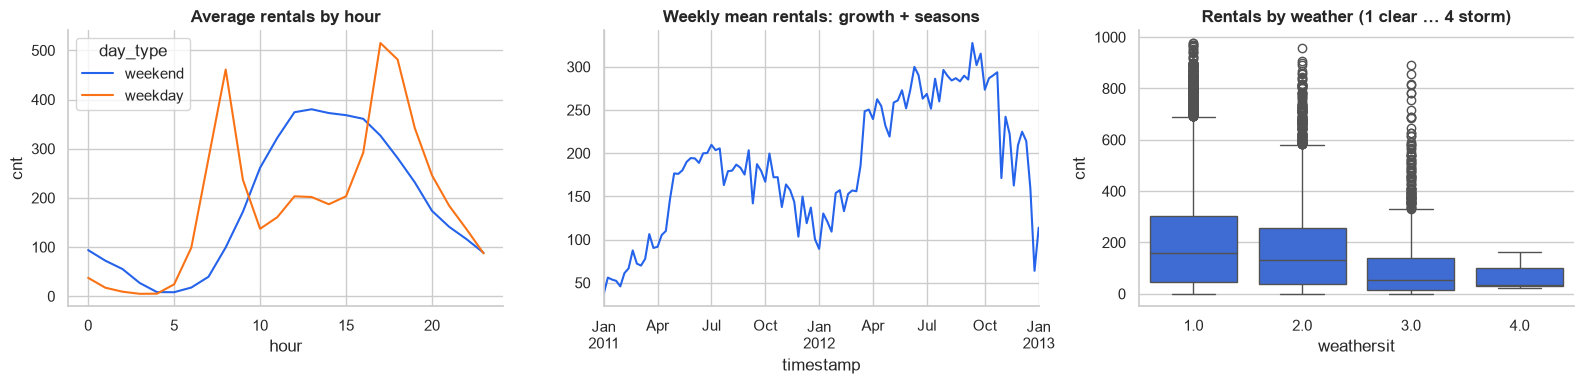

In [6]:
eda = df.assign(hour=df.index.hour, weekday=df.index.dayofweek, day_type=np.where(df.index.dayofweek < 5, "weekday", "weekend"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.lineplot(data=eda, x="hour", y="cnt", hue="day_type", ax=axes[0], errorbar=None).set(title="Average rentals by hour")
df["cnt"].resample("W").mean().plot(ax=axes[1], title="Weekly mean rentals: growth + seasons")
sns.boxplot(data=eda, x="weathersit", y="cnt", ax=axes[2]).set(title="Rentals by weather (1 clear … 4 storm)")
plt.tight_layout(); plt.show()

**What a model must learn:**
- 🕗 **Two daily patterns**: on weekdays, commute peaks at 8 a.m. and 5-6 p.m.; on weekends, a smooth afternoon bump.
- 📈 **Growth**: 2012 is much busier than 2011 (the service became popular).
- 🌦️ **Seasons and weather**: cold, rain and storms kill demand.

## 3. Frame the forecast: what do we know at midnight? 🕛

This is the most important (and most often skipped) step. At midnight, when we forecast hours 0-23 of the next day:
- we know the **calendar** of tomorrow (hour, weekday, holiday) ✅
- we know all rentals **up to midnight**, so any value at least 24 hours before the target hour ✅
- we do **not** know tomorrow's rentals, of course ❌
- tomorrow's **weather** is only known through a *forecast*. Here we only have the real weather, so using it would be
  an optimistic "perfect weather forecast". We will measure its impact separately and flag it.

Features that respect this rule can predict the 24 hours **directly**, without feeding predictions back.

**Validation:** the test period is December 2012. We never shuffle; all training data is before the test.

**Metrics:** MAE (average error in bikes per hour) and RMSLE, the metric of the Kaggle competition. RMSLE compares
`log(1 + y)`: being off by 50 bikes matters more at 3 a.m. (expected 10) than at 5 p.m. (expected 800). Since we
optimise RMSLE, we will train the models on `log1p(cnt)`.

In [7]:
def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

def rmsle(y, p):
    return float(np.sqrt(np.mean((np.log1p(np.asarray(y)) - np.log1p(np.clip(np.asarray(p), 0, None))) ** 2)))

TEST_START = pd.Timestamp("2012-12-01")
test_idx = df.index[df.index >= TEST_START]
y_test = df.loc[test_idx, "cnt"]
print(f"Test: {len(test_idx)} hours = {len(test_idx) // 24} days to forecast, one day at a time")

lb = Leaderboard("bike_demand", metric="RMSLE", higher_is_better=False)
preds = {}   # store every model's test forecast to compare and ensemble later

def log_model(name, p, **extra):
    p = pd.Series(np.clip(np.asarray(p, dtype=float), 0, None), index=test_idx)
    preds[name] = p
    lb.add(name, rmsle(y_test, p), MAE=round(mae(y_test, p), 1), **extra)

Test: 744 hours = 31 days to forecast, one day at a time


## 4. Baselines 🧱

- **Same hour yesterday** (`lag 24`): tomorrow looks like today.
- **Same hour last week** (`lag 168`): next Monday looks like last Monday, which respects the weekly cycle.

In [8]:
log_model("Baseline: same hour yesterday", df["cnt"].shift(24).loc[test_idx])
log_model("Baseline: same hour last week", df["cnt"].shift(168).loc[test_idx])
lb.show()

📋 Baseline: same hour yesterday: RMSLE = 0.80558
📋 Baseline: same hour last week: RMSLE = 0.82363


,,model,RMSLE,MAE
rank,,,,
1,🥇,Baseline: same hour yesterday,0.80558,60.0
2,🥈,Baseline: same hour last week,0.82363,65.1


## 5. Gradient boosting with lag features: the direct strategy 🌳

Gradient boosting doesn't "know" about time. We turn the series into a **tabular** problem: each hour becomes a row
with features describing its context. This trick (with LightGBM) won the famous **M5 forecasting competition**
(Walmart sales, 2020).

> 🛠️ **Which library?** In competitions the usual choice is **LightGBM** (`LGBMRegressor`). Here we use
> scikit-learn's `HistGradientBoostingRegressor`, the same algorithm family (histogram-based gradient boosting,
> inspired by LightGBM) with the same API, because this notebook also loads PyTorch for Chronos, and on macOS
> LightGBM/XGBoost and PyTorch ship two copies of the OpenMP library that crash when loaded in the same Python
> process. In a notebook without PyTorch, swap in LightGBM freely: the code is identical.

Our features, all available at midnight:
- **calendar**: hour, day of week, month, holiday, weekend flag
- **lags** ≥ 24 h: the same hour 1, 2 and 7 days before
- **rolling statistics**: mean of the same hour over the last 7 days, mean of the previous 24 h window
- *(optional, flagged)* **weather** of the target hour

In [9]:
def make_features(data: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=data.index)
    X["hour"] = data.index.hour
    X["dayofweek"] = data.index.dayofweek
    X["month"] = data.index.month
    X["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
    X["holiday"] = data["holiday"]
    X["year"] = data.index.year - 2011                       # captures the growth
    y = data["cnt"]
    for lag in (24, 48, 168, 336):
        X[f"lag_{lag}"] = y.shift(lag)
    X["same_hour_mean_7d"] = sum(y.shift(24 * k) for k in range(1, 8)) / 7
    X["prev_day_mean"] = y.shift(24).rolling(24).mean()
    X["prev_day_max"] = y.shift(24).rolling(24).max()
    for c in weather_cols:
        X[c] = data[c]
    return X

X_all = make_features(df)
y_all = np.log1p(df["cnt"])
calendar_lag_cols = [c for c in X_all.columns if c not in weather_cols]

train_mask = (X_all.index < TEST_START) & X_all["lag_336"].notna()
X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test = X_all.loc[test_idx]
print(f"Training rows: {len(X_train)}  ·  features: {X_all.shape[1]}")
X_train.tail(3)

Training rows: 16464  ·  features: 18


,hour,dayofweek,month,is_weekend,holiday,year,lag_24,lag_48,lag_168,lag_336,same_hour_mean_7d,prev_day_mean,prev_day_max,weathersit,temp,atemp,hum,windspeed
timestamp,,,,,,,,,,,,,,,,,,
2012-11-30 21:00:00,21,4,11,0,0.0,1,208.0,223.0,98.0,178.0,147.714286,219.750000,679.0,1.0,0.3,0.3182,0.75,0.0896
2012-11-30 22:00:00,22,4,11,0,0.0,1,151.0,154.0,79.0,162.0,103.285714,219.625000,679.0,1.0,0.3,0.3333,0.75,0.0000
2012-11-30 23:00:00,23,4,11,0,0.0,1,130.0,78.0,67.0,128.0,72.142857,221.791667,679.0,2.0,0.3,0.3182,0.75,0.0896


### Time-series cross-validation
Before touching the test set, we validate on the training period with `TimeSeriesSplit`: each fold trains on the past
and validates on the **following** two weeks, like walking forward in time.

```
fold 1: [train..........][val]
fold 2: [train.............][val]
fold 3: [train................][val]
```

In [10]:
from sklearn.model_selection import TimeSeriesSplit

params = dict(max_iter=300, learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=20,
              l2_regularization=1.0, random_state=SEED)

def gbm():
    return HistGradientBoostingRegressor(**params)
tscv = TimeSeriesSplit(n_splits=5, test_size=24 * 14)
for cols, name in [(calendar_lag_cols, "calendar + lags"), (list(X_all.columns), "calendar + lags + weather")]:
    scores = []
    for tr, va in tscv.split(X_train):
        m = gbm().fit(X_train.iloc[tr][cols], y_train.iloc[tr])
        scores.append(rmsle(np.expm1(y_train.iloc[va]), np.expm1(m.predict(X_train.iloc[va][cols]))))
    print(f"CV RMSLE ({name:<26}): {np.mean(scores):.3f} ± {np.std(scores):.3f}   folds: {np.round(scores, 3)}")

CV RMSLE (calendar + lags           ): 0.676 ± 0.486   folds: [0.373 0.37  1.641 0.46  0.536]


CV RMSLE (calendar + lags + weather ): 0.566 ± 0.390   folds: [0.303 0.272 1.328 0.428 0.502]


The CV confirms that the weather helps. Look at the folds: one of them is terrible for both models. It is the
fortnight of **Hurricane Sandy** (Oct 29-30, 2012), when the system shut down and rentals fell to zero. No model could
have predicted that from the past, and RMSLE punishes zeros predicted as hundreds very hard. This is why you report
the **spread** across folds, not only the mean, and why you always look at the worst fold.

Now we train on the whole training period and forecast December.

In [11]:
model_cal = gbm().fit(X_train[calendar_lag_cols], y_train)
log_model("GBM direct (calendar + lags)", np.expm1(model_cal.predict(X_test[calendar_lag_cols])))

model_wx = gbm().fit(X_train, y_train)
log_model("GBM direct + weather (oracle ⚠️)", np.expm1(model_wx.predict(X_test)))
lb.show()

📋 GBM direct (calendar + lags): RMSLE = 0.56974  👑 new best!


📋 GBM direct + weather (oracle ⚠️): RMSLE = 0.47619  👑 new best!


,,model,RMSLE,MAE
rank,,,,
1,🥇,GBM direct + weather (oracle ⚠️),0.47619,37.7
2,🥈,GBM direct (calendar + lags),0.56974,42.7
3,🥉,Baseline: same hour yesterday,0.80558,60.0
4,,Baseline: same hour last week,0.82363,65.1


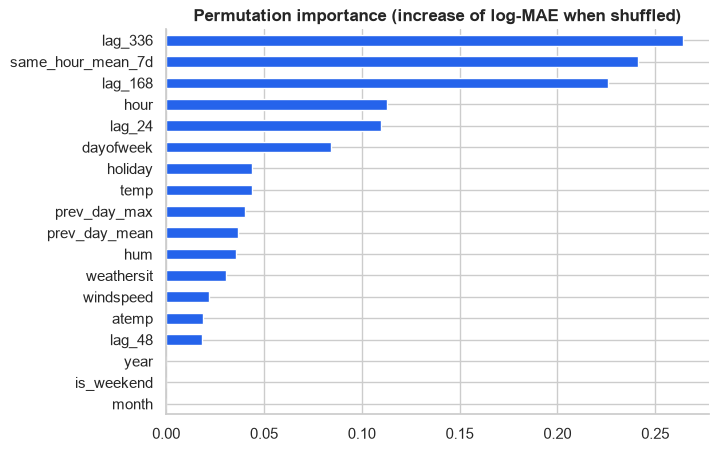

In [12]:
# Which features matter? Permutation importance on the last 4 training weeks:
# shuffle one column, measure how much worse the model gets.
from sklearn.inspection import permutation_importance
recent = X_train.index >= TEST_START - pd.Timedelta(days=28)
imp = permutation_importance(model_wx, X_train[recent], y_train[recent], n_repeats=5, random_state=SEED,
                             scoring="neg_mean_absolute_error")
pd.Series(imp.importances_mean, index=X_train.columns).sort_values().plot.barh(
    figsize=(7, 5), title="Permutation importance (increase of log-MAE when shuffled)")
plt.show()

In [13]:
checkpoint("bike/boosting", xp=60)

✅ Checkpoint · bike/boosting (+60 XP)
   ██████████████░░░░░░░░░░ 60/100 XP


## 6. The recursive strategy 🔁

The other way to forecast 24 hours: train a model to predict **one hour ahead** using the very latest values
(lag 1, lag 2…), then **feed its own prediction back** as input for the next hour, 24 times.

- 👍 it uses the freshest information (what happened one hour ago is very informative),
- 👎 errors **accumulate**: a mistake at 1 a.m. pollutes the inputs for 2 a.m., and so on.

In [14]:
REC_LAGS = (1, 2, 3, 24, 168)

def rec_features(y: np.ndarray, t: int, ts: pd.Timestamp) -> list:
    return [ts.hour, ts.dayofweek, ts.month, int(ts.dayofweek >= 5), ts.year - 2011] + [y[t - l] for l in REC_LAGS]

y_series = np.log1p(df["cnt"].to_numpy())
times = df.index
start = 400
train_end = times.get_loc(TEST_START)
Xr = np.array([rec_features(y_series, t, times[t]) for t in range(start, train_end)])
model_rec = gbm().fit(Xr, y_series[start:train_end])

origins = list(range(train_end, len(times), 24))             # forecast origins: each midnight of December
work = np.tile(y_series, (len(origins), 1))                  # one copy of the history per origin
for h in range(24):                                          # step h: predict hour h of every day at once
    rows = [rec_features(work[d], o + h, times[o + h]) for d, o in enumerate(origins)]
    step_pred = model_rec.predict(np.array(rows))
    for d, o in enumerate(origins):
        work[d, o + h] = step_pred[d]                        # the prediction becomes an input for hour h+1
rec_pred = np.concatenate([work[d, o:o + 24] for d, o in enumerate(origins)])
log_model("GBM recursive (lags 1-3, 24, 168)", np.expm1(rec_pred))

📋 GBM recursive (lags 1-3, 24, 168): RMSLE = 0.66611


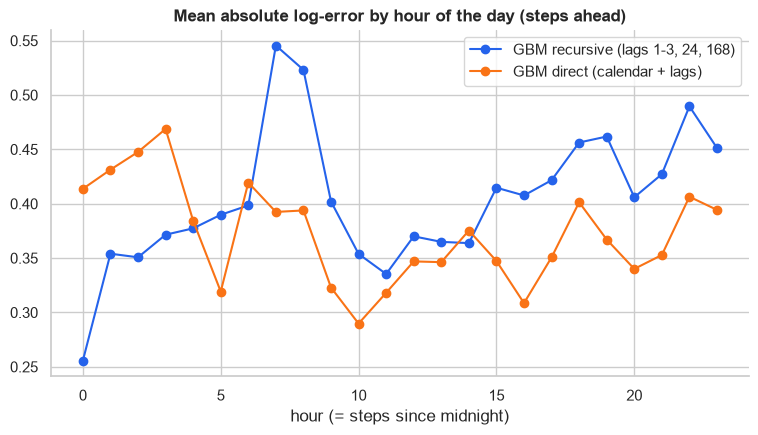

In [15]:
# How does the error grow with the hour of the day (= steps since the forecast origin)?
err = pd.DataFrame({name: (np.log1p(preds[name]) - np.log1p(y_test)).abs().groupby(test_idx.hour).mean()
                    for name in ["GBM recursive (lags 1-3, 24, 168)", "GBM direct (calendar + lags)"]})
err.plot(marker="o", title="Mean absolute log-error by hour of the day (steps ahead)", xlabel="hour (= steps since midnight)")
plt.show()

Compare the first hours (where the recursive model still sees *real* recent values) with the rest of the day (where
its inputs are only its own predictions). Over the whole day, the direct model wins here. In practice, competitors
often combine both ideas (one direct model per horizon, or recursive features refreshed whenever new data arrives).

## 7. Chronos: a foundation model, zero training 🤖

In 2024, Amazon researchers released **Chronos**, a family of models pretrained on hundreds of thousands of time
series (energy, traffic, weather, sales…). Like a language model predicts the next word, Chronos predicts the next
values of **any** series it has never seen: this is **zero-shot forecasting**. We use *Chronos-Bolt (small)*, a fast
version of ~48M parameters that also returns **quantiles** (a full uncertainty band) for free.

It only sees the history of rentals: no calendar, no weather. Can it compete with our carefully engineered model?

In [16]:
import torch
from chronos import BaseChronosPipeline

device = get_device()
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()
chronos = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map=device, torch_dtype=torch.float32)

CONTEXT = 24 * 42                                           # the last 6 weeks of history
counts = df["cnt"].to_numpy(dtype=np.float32)
contexts = [torch.tensor(counts[o - CONTEXT:o]) for o in origins]
quantiles, mean = chronos.predict_quantiles(contexts, prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])
q = quantiles.numpy().reshape(-1, 3)                      # (31 days × 24 h, 3 quantiles)
log_model("Chronos-Bolt small (zero-shot)", q[:, 1])
lb.show()

W1120 22:38:36.513000 73810 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


⚙️  Using device: mps  (Apple Silicon GPU (Metal))


📋 Chronos-Bolt small (zero-shot): RMSLE = 0.68960


,,model,RMSLE,MAE
rank,,,,
1,🥇,GBM direct + weather (oracle ⚠️),0.47619,37.7
2,🥈,GBM direct (calendar + lags),0.56974,42.7
3,🥉,"GBM recursive (lags 1-3, 24, 168)",0.66611,49.4
4,,Chronos-Bolt small (zero-shot),0.68960,37.2
5,,Baseline: same hour yesterday,0.80558,60.0
6,,Baseline: same hour last week,0.82363,65.1


Look closely at the two metrics: Chronos has a weaker **RMSLE** than our trained models but one of the best **MAE**.
It is excellent on the busy hours (large absolute numbers) and less precise at night, where an error of 20 bikes on an
expected 10 is a disaster in log scale. **The metric decides the winner**: always optimise the one you are scored on.
And remember Chronos saw no calendar, no weather, and was never trained on bikes!

## 8. Ensemble and the final picture 🤝

Our gradient boosting model (with domain features) and Chronos (with patterns learnt from thousands of other series)
are very different models, so their errors should be partly independent. Let's average them.

In [17]:
ens = (preds["GBM direct (calendar + lags)"] + preds["Chronos-Bolt small (zero-shot)"]) / 2
log_model("Ensemble: GBM direct + Chronos", ens)
board = lb.show()
board

📋 Ensemble: GBM direct + Chronos: RMSLE = 0.53952


,,model,RMSLE,MAE
rank,,,,
1,🥇,GBM direct + weather (oracle ⚠️),0.47619,37.7
2,🥈,Ensemble: GBM direct + Chronos,0.53952,34.9
3,🥉,GBM direct (calendar + lags),0.56974,42.7
4,,"GBM recursive (lags 1-3, 24, 168)",0.66611,49.4
5,,Chronos-Bolt small (zero-shot),0.68960,37.2
6,,Baseline: same hour yesterday,0.80558,60.0
7,,Baseline: same hour last week,0.82363,65.1


The ensemble gets the **best MAE** of all and the best RMSLE among models that do not use the (optimistic) real
weather: two different "views" of the series beat each of them alone.

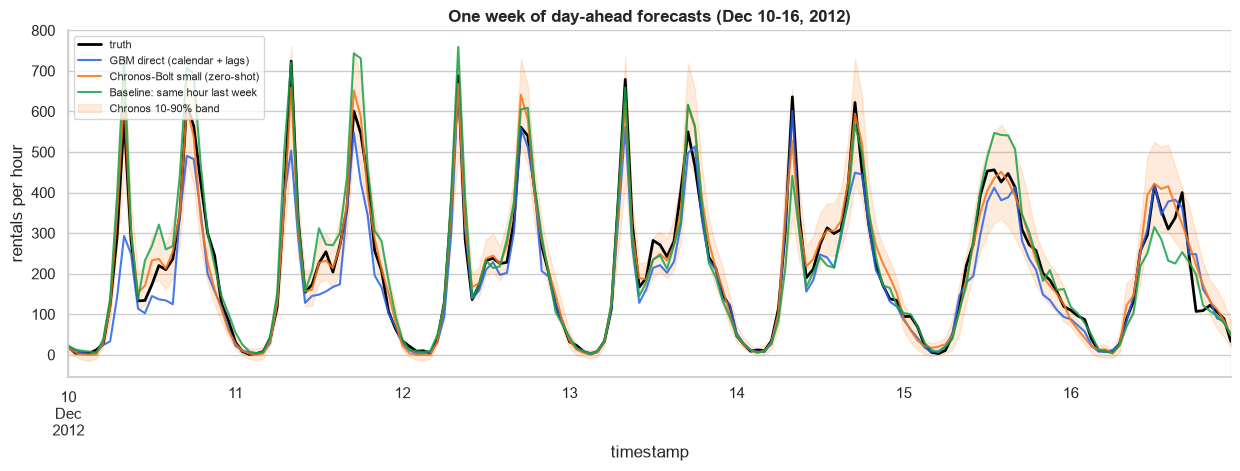

Share of real values inside Chronos' 10-90% band: 78% (ideal: 80%)


In [18]:
week = slice("2012-12-10", "2012-12-16")
fig, ax = plt.subplots(figsize=(15, 4.5))
y_test[week].plot(ax=ax, color="black", lw=2, label="truth")
for name in ["GBM direct (calendar + lags)", "Chronos-Bolt small (zero-shot)", "Baseline: same hour last week"]:
    preds[name][week].plot(ax=ax, label=name, alpha=0.85)
band = pd.DataFrame(q, index=test_idx)[week]
ax.fill_between(band.index, band[0], band[2], alpha=0.15, color="tab:orange", label="Chronos 10-90% band")
ax.set(title="One week of day-ahead forecasts (Dec 10-16, 2012)", ylabel="rentals per hour"); ax.legend(loc="upper left", fontsize=8)
plt.show()

inside = ((y_test.to_numpy() >= q[:, 0]) & (y_test.to_numpy() <= q[:, 2])).mean()
print(f"Share of real values inside Chronos' 10-90% band: {inside:.0%} (ideal: 80%)")

## 🏁 What did we learn?

- **Framing beats modelling**: deciding what is known at forecast time defined our features and kept us leak-free.
- **Baselines are strong** in seasonal data, but lag features + gradient boosting beat them by a wide margin.
- **Weather** (an exogenous variable) helps, but remember: in production you would only have a weather *forecast*.
- **Direct vs recursive**: recursive shines for the first steps, then accumulates errors.
- **Foundation models** like Chronos give a strong forecast with zero feature engineering and calibrated uncertainty;
  ensembling them with a tuned model is a very practical recipe.

### 🚀 Your turn (bonus XP)
1. Add `casual` and `registered` as two separate targets (tourists vs commuters behave very differently), forecast
   each and sum them. Does RMSLE improve?
2. Give Chronos a longer context (`CONTEXT = 24 * 90`). Better?
3. Replace oracle weather by a "noisy forecast": add random noise to `temp` in the test features. How fast does the gain
   vanish?
4. Try the newer `amazon/chronos-2` model, which can also use covariates (see the chronos-forecasting docs).
5. Compete: Kaggle's [Bike Sharing Demand](https://www.kaggle.com/competitions/bike-sharing-demand) (late submissions
   still score) uses this very dataset.

In [19]:
checkpoint("bike/complete", xp=190)
badge("Demand Forecaster", "🚲")
progress()

✅ Checkpoint · bike/complete (+190 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██████████████████░░░░░░ 250/300 XP
╔══════════════════════════════════════╗
║ 🚲  BADGE UNLOCKED: Demand Forecaster ║
╚══════════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 2
Badges: 🚲 Demand Forecaster
